# Table of Contents
- 1. Correlation Matrix Heatmaps (Pearson, Spearman, Cramér's V)
- 2. Variance Inflation Factor (VIF) for Collinearity
- 3. Partial Correlation Analysis
- 4. Non-Linear Association Detection (Maximal Information Coefficient)

In [6]:
# Global Imports and Runtime Visual Configuration
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Visual styling settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

print("Global libraries for correlation and collinearity discovery loaded successfully.")

Global libraries for correlation and collinearity discovery loaded successfully.


1. Correlation Matrix Heatmaps (Pearson, Spearman, Cramér's V)
$$r_{xy} = \frac{\sum_{i=1}^N (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^N (x_i - \bar{x})^2 \sum_{i=1}^N (y_i - \bar{y})^2}}$$


   feature_1  feature_2  feature_3
0   0.374540   0.062858   0.231630
1   0.950714   1.272821   0.783797
2   0.731994   0.628712   0.614902
____________________________________________________________
Correlation Matrix:
            feature_1  feature_2  feature_3
feature_1   1.000000  -0.034033   0.915235
feature_2  -0.034033   1.000000   0.053721
feature_3   0.915235   0.053721   1.000000


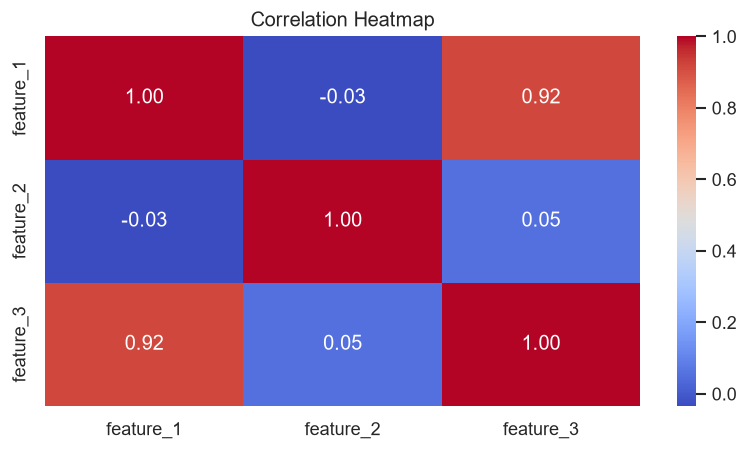

In [7]:
np.random.seed(42)
df_corr = pd.DataFrame({
    'feature_1': np.random.rand(100),
    'feature_2': np.random.rand(100) * 2
})
df_corr['feature_3'] = df_corr['feature_1'] * 0.8 + np.random.normal(0, 0.1, 100)
print(df_corr.head(3))
print("_" * 60)
corr_matrix = df_corr.corr(method='pearson') # method : 'pearson', 'kendall', 'spearman'
print("Correlation Matrix:\n", corr_matrix)

# visualization
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap")
plt.show()

## 2. Variance Inflation Factor (VIF) for Collinearity
$$\text{VIF}_j = \frac{1}{1 - R_j^2}$$

   x1    x2  x3
0   1   2.1   1
1   2   3.9   0
2   3   6.2   3
3   4   7.9   2
4   5  10.1   5
____________________________________________________________
  feature     VIF
0      x1  5323.5
1      x2  6010.8
2      x3    33.3


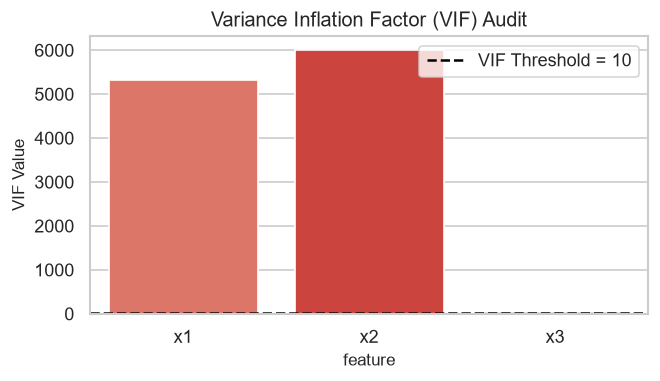

In [8]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
X_vif = pd.DataFrame({
    'x1': [1, 2, 3, 4, 5],
    'x2': [2.1, 3.9, 6.2, 7.9, 10.1], # Perfectly collinear with x1
    'x3': [1, 0, 3, 2, 5]
})
print(X_vif)
print("_" * 60)

vif_data = pd.DataFrame()
vif_data["feature"] = X_vif.columns
vif_data["VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
print(vif_data)

# visualization
# Visualization
plt.figure(figsize=(6, 3))
sns.barplot(x='feature', y='VIF', hue='feature', data=vif_data, palette='Reds_d', legend=False, errorbar=None)
plt.axhline(y=10, color='black', linestyle='--', label='VIF Threshold = 10')
plt.title('Variance Inflation Factor (VIF) Audit')
plt.ylabel('VIF Value')
plt.legend()
plt.show()

   Size_SqFt  Num_Bedrooms
0       1500             3
1       1600             3
2       1700             4
3       1800             4
4       1900             5
____________________________________________________________
        feature       VIF
0     Size_SqFt  9.333333
1  Num_Bedrooms  9.333333


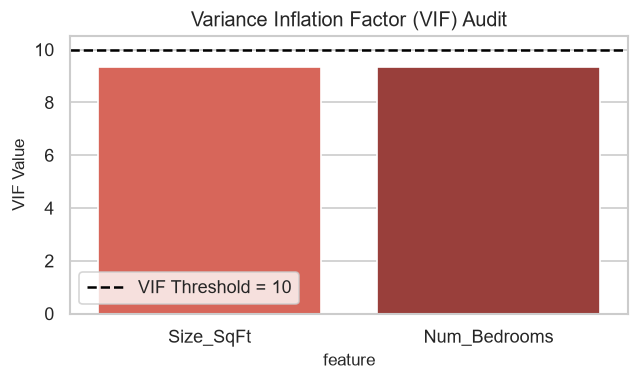

In [9]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
X_vif = pd.DataFrame({
    'Size_SqFt': [1500, 1600, 1700, 1800, 1900],
    'Num_Bedrooms': [3, 3, 4, 4, 5],
    # 'Size_SqMeters': [139.35, 148.64, 157.93, 167.22, 176.51]
})
print(X_vif)
print("_" * 60)

vif_data = pd.DataFrame()
vif_data["feature"] = X_vif.columns
vif_data["VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
print(vif_data)

# visualization
# Visualization
plt.figure(figsize=(6, 3))
sns.barplot(x='feature', y='VIF', hue='feature', data=vif_data, palette='Reds_d', legend=False, errorbar=None)
plt.axhline(y=10, color='black', linestyle='--', label='VIF Threshold = 10')
plt.title('Variance Inflation Factor (VIF) Audit')
plt.ylabel('VIF Value')
plt.legend()
plt.show()

# 3. Partial Correlation Analysis

#### - Partial correlation measures the degree of association between two random variables while removing the confounding linear effect of one or more controlling variables.

In [10]:
from pingouin import partial_corr
# 1. Create data for 5 bowlers
data = {
    'bowler': ['Anil', 'Bumrah', 'Chahal', 'Dhawan', 'Shami'],
    'overs': [10, 20, 40, 50, 60],
    'runs': [75, 140, 290, 370, 460],
    'wickets': [3, 7, 12, 15, 19],
}
df = pd.DataFrame(data)
print(df)
print("_" * 60)
# 2. Regular Correlation: Runs vs. Wickets (ignoring overs)
regular_corr = df['runs'].corr(df['wickets'])
print(
    f'\n1. Regular Correlation (Runs vs Wickets): {regular_corr:.4f}'
)  # Will be very close to +1.0!

# 3. Partial Correlation: Runs vs. Wickets (controlling for overs)
partial_corr_result = partial_corr(data=df, x='runs', y='wickets', covar='overs')
print(
    f'\n2. Partial Correlation (Runs vs Wickets controlling for Overs): {partial_corr_result["r"].values[0]:.4f}'
)

   bowler  overs  runs  wickets
0    Anil     10    75        3
1  Bumrah     20   140        7
2  Chahal     40   290       12
3  Dhawan     50   370       15
4   Shami     60   460       19
____________________________________________________________

1. Regular Correlation (Runs vs Wickets): 0.9964

2. Partial Correlation (Runs vs Wickets controlling for Overs): 0.2837


In [11]:
from scipy.stats import pearsonr,linregress
data1 = {
    'bowler': ['Anil', 'Bumrah', 'Chahal', 'Dhawan', 'Shami'],
    'overs': [10, 20, 40, 50, 60],
    'runs': [75, 140, 290, 370, 460],
    'wickets': [3, 7, 12, 15, 19],
}
df1 = pd.DataFrame(data1)

slope_r, intercept_r, _, _, _ = linregress(df1['overs'], df1['runs'])
predicted_runs = slope_r * df1['overs'] + intercept_r
residual_runs = df1['runs'] - predicted_runs

slope_w, intercept_w, _, _, _ = linregress(df1['overs'], df1['wickets'])
predicted_wickets = slope_w * df1['overs'] + intercept_w
residual_wickets = df1['wickets'] - predicted_wickets

partial_r,p_value = pearsonr(residual_runs, residual_wickets)
print(f'Partial Correlation (Runs vs Wickets controlling for Overs): {partial_r:.4f}, p-value: {p_value:.4f}')

Partial Correlation (Runs vs Wickets controlling for Overs): 0.2837, p-value: 0.6437


## - 4 .Non-Linear Association Detection (Maximal Information Coefficient)

Pearson Correlation (Non-linear relationship): 0.0007


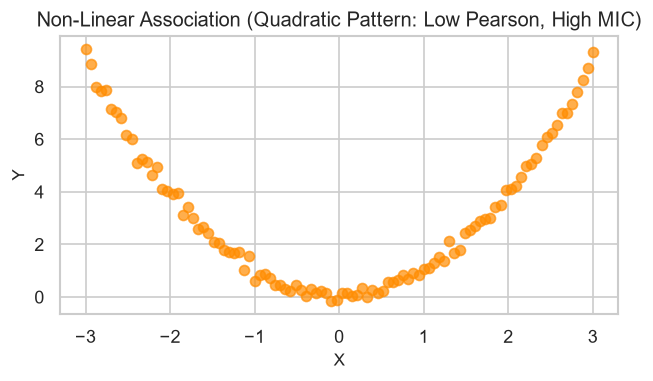

In [12]:
x_nonlin = np.linspace(-3, 3, 100)
y_nonlin = x_nonlin**2 + np.random.normal(0, 0.2, 100)
pearson_val = pd.Series(x_nonlin).corr(pd.Series(y_nonlin))
print(f'Pearson Correlation (Non-linear relationship): {pearson_val:.4f}')

# Visualization
plt.figure(figsize=(6, 3))
plt.scatter(x_nonlin, y_nonlin, color='darkorange', alpha=0.7)
plt.title('Non-Linear Association (Quadratic Pattern: Low Pearson, High MIC)')
plt.xlabel('X')
plt.ylabel('Y')
plt.show()